In [23]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
import kagglehub
import os
import matplotlib.pyplot as plt
from sklearn.utils import compute_class_weight


from keras.layers import Dense, Flatten, Rescaling,BatchNormalization
from keras.models import Sequential

from keras.callbacks import EarlyStopping
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten
from keras.utils import to_categorical

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [9]:
path = kagglehub.dataset_download("msambare/fer2013")

Using Colab cache for faster access to the 'fer2013' dataset.


## code

##### the Problem
The model classifies facial images into seven classes: angry, disgust, fear, happy, neutral, sad, and surprise. It learns to identify different facial features to predict the correct class. This can be useful in applications that recognize facial emotions using a camera.

In [216]:
# create a list of teh 7 classes

In [10]:
#Load FER2013 images data and split the data into training, validation, and load the test set.
train_ds = tf.keras.utils.image_dataset_from_directory(
    "/kaggle/input/fer2013/train",
    validation_split=0.15, subset="training", seed=42,
    color_mode="grayscale", image_size=(48, 48),
    batch_size=64, label_mode="categorical")

val_ds = tf.keras.utils.image_dataset_from_directory(
    "/kaggle/input/fer2013/train",
    validation_split=0.15, subset="validation", seed=42,
    color_mode="grayscale", image_size=(48, 48),
    batch_size=64, label_mode="categorical")

test_ds = tf.keras.utils.image_dataset_from_directory(
    "/kaggle/input/fer2013/test", color_mode="grayscale", image_size=(48, 48),
    batch_size=64, label_mode="categorical", shuffle=False)

Found 28709 files belonging to 7 classes.
Using 24403 files for training.
Found 28709 files belonging to 7 classes.
Using 4306 files for validation.
Found 7178 files belonging to 7 classes.


In [12]:
class_names = train_ds.class_names
print(class_names)

['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


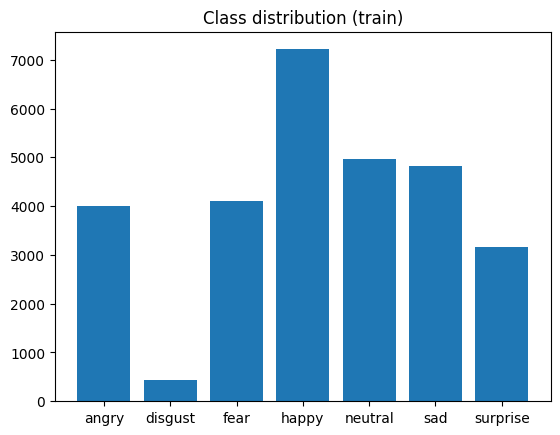

In [15]:
# bar chart for the number of images in each class
counts = {c: len(os.listdir(f"{p}/{c}")) for c in sorted(os.listdir(p))}
plt.bar(counts.keys(), counts.values())
plt.title("Class distribution (train)")
plt.show()

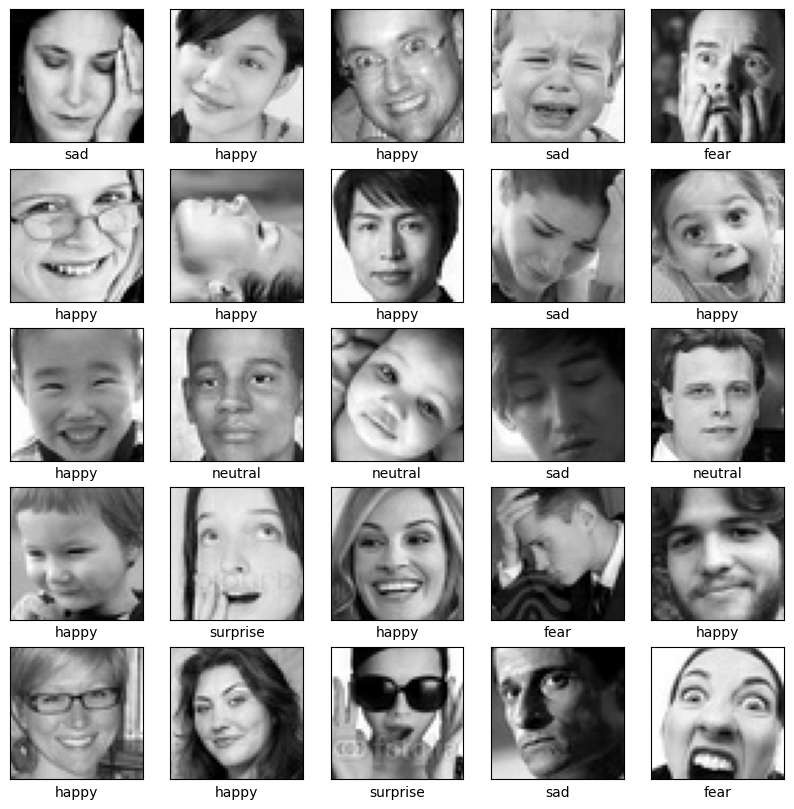

In [16]:
# sample of the images
class_names= ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

plt.figure(figsize=(10, 10))
for x, y in train_ds.take(1):
    for i in range(25):
        plt.subplot(5, 5, i + 1)
        plt.imshow(x[i, :, :, 0], cmap="gray")
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.xlabel(class_names[y[i].numpy().argmax()])
plt.show()

In [17]:
#Check image dimensions and color channels
for image_batch, labels_batch in train_ds:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

(64, 48, 48, 1)
(64, 7)


In [18]:
# normalization_layer = tf.keras.layers.Rescaling(1./255)

In [19]:
# train_ds = train_ds.map(lambda x, y: (norm(x), y))
# val_ds   = val_ds.map(lambda x, y: (norm(x), y))
# test_ds  = test_ds.map(lambda x, y: (norm(x), y))

In [20]:
# model: Build and compile the baseline NN model

In [21]:
model = Sequential([
    Rescaling(1./255, input_shape=(48, 48, 1)),
    Flatten(),
    BatchNormalization(),
    Dense(200, activation="relu"),
    Dense(100, activation="relu"),
    Dense(80, activation="relu"),
    Dense(50, activation="relu"),
    Dense(7, activation="softmax")
])

model.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [24]:
#compute class weight for y_train

y_train= np.concatenate([y.numpy() for x, y in train_ds], axis=0)
y_train= np.argmax(y_train, axis=1)

classes=np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
# convert the c_weights to dictionay holding class and weight


class_weight_dict= dict(zip(classes, class_weights))

print(class_weight_dict)

{np.int64(0): np.float64(1.0199364707849201), np.int64(1): np.float64(8.961806830701432), np.int64(2): np.float64(1.0063922797756517), np.int64(3): np.float64(0.5645575477154424), np.int64(4): np.float64(0.8251225697379544), np.int64(5): np.float64(0.8542374067980537), np.int64(6): np.float64(1.3150293689712778)}


In [25]:
# configure EarlyStopping parameters
early_stoping=EarlyStopping(monitor='val_loss',patience=10,restore_best_weights=True)

In [26]:
from keras.callbacks import ModelCheckpoint

In [27]:
checkpoint_filepath = '/tmp/ckpt/checkpoint.model.keras'

model_checkpoint_callback = ModelCheckpoint(
    filepath=checkpoint_filepath,
    monitor='val_loss',
    mode='min',
    save_best_only=True)

In [28]:
# fit the model

In [29]:
history=model.fit(train_ds , validation_data=val_ds, epochs=30, callbacks=[early_stoping, model_checkpoint_callback],class_weight=class_weight_dict
)

Epoch 1/30
382/382 ━━━━━━━━━━━━━━━━━━━━ 26s 61ms/step - accuracy: 0.2381 - loss: 1.8931 - val_accuracy: 0.2406 - val_loss: 1.8637
Epoch 2/30
382/382 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - accuracy: 0.2878 - loss: 1.7830 - val_accuracy: 0.3000 - val_loss: 1.7699
Epoch 3/30
382/382 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.3143 - loss: 1.7080 - val_accuracy: 0.3214 - val_loss: 1.7387
Epoch 4/30
382/382 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.3376 - loss: 1.6376 - val_accuracy: 0.3323 - val_loss: 1.7003
Epoch 5/30
382/382 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.3522 - loss: 1.5811 - val_accuracy: 0.3593 - val_loss: 1.6510
Epoch 6/30
382/382 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - accuracy: 0.3702 - loss: 1.5344 - val_accuracy: 0.3481 - val_loss: 1.6930
Epoch 7/30
382/382 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.3774 - loss: 1.4822 - val_accuracy: 0.3528 - val_loss: 1.6437
Epoch 8/30
382/382 ━━━━━━━━━━━━━━━━━━━━ 16s 42ms/step - accuracy: 0.3868 - loss: 1.4400 - 

In [30]:
# model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 2304)           │         9,216 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 200)            │       461,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        20,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 80)             │         8,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 50)             │         4,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 7)              │           357 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,499,195 (5.72 MB)

 Trainable params: 498,195 (1.90 MB)

 Non-trainable params: 4,608 (18.00 KB)

 Optimizer params: 996,392 (3.80 MB)

In [31]:
# convert the hisyory data into daat frame

In [32]:
hist=pd.DataFrame(history.history)

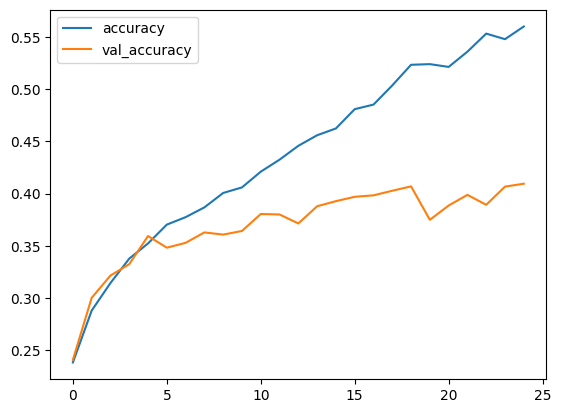

In [33]:
hist[["accuracy", "val_accuracy"]].plot();

In [34]:
# there is overlapping in this plot

In [35]:
#extract the true class labels from the test dataset
y_test= np.concatenate([y.numpy().argmax(axis=1) for x, y in test_ds])

In [36]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [37]:
# performance of test dataset

In [44]:
model.evaluate(test_ds)

113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.3936 - loss: 1.5789


[1.578873634338379, 0.3935636579990387]

In [45]:
y_pred=model.predict(test_ds).argmax(axis=1)


113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step


In [46]:
#ConfusionMatrix

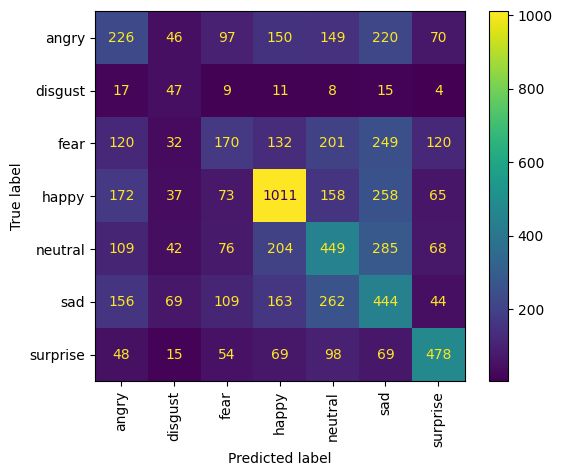

In [47]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names, xticks_rotation='vertical');

In [48]:
# classification report for test

In [49]:
print(classification_report(y_test, y_pred, target_names=class_names))

              precision    recall  f1-score   support

       angry       0.27      0.24      0.25       958
     disgust       0.16      0.42      0.24       111
        fear       0.29      0.17      0.21      1024
       happy       0.58      0.57      0.58      1774
     neutral       0.34      0.36      0.35      1233
         sad       0.29      0.36      0.32      1247
    surprise       0.56      0.58      0.57       831

    accuracy                           0.39      7178
   macro avg       0.36      0.38      0.36      7178
weighted avg       0.40      0.39      0.39      7178



In [50]:
# sample of image with true label and predict labels

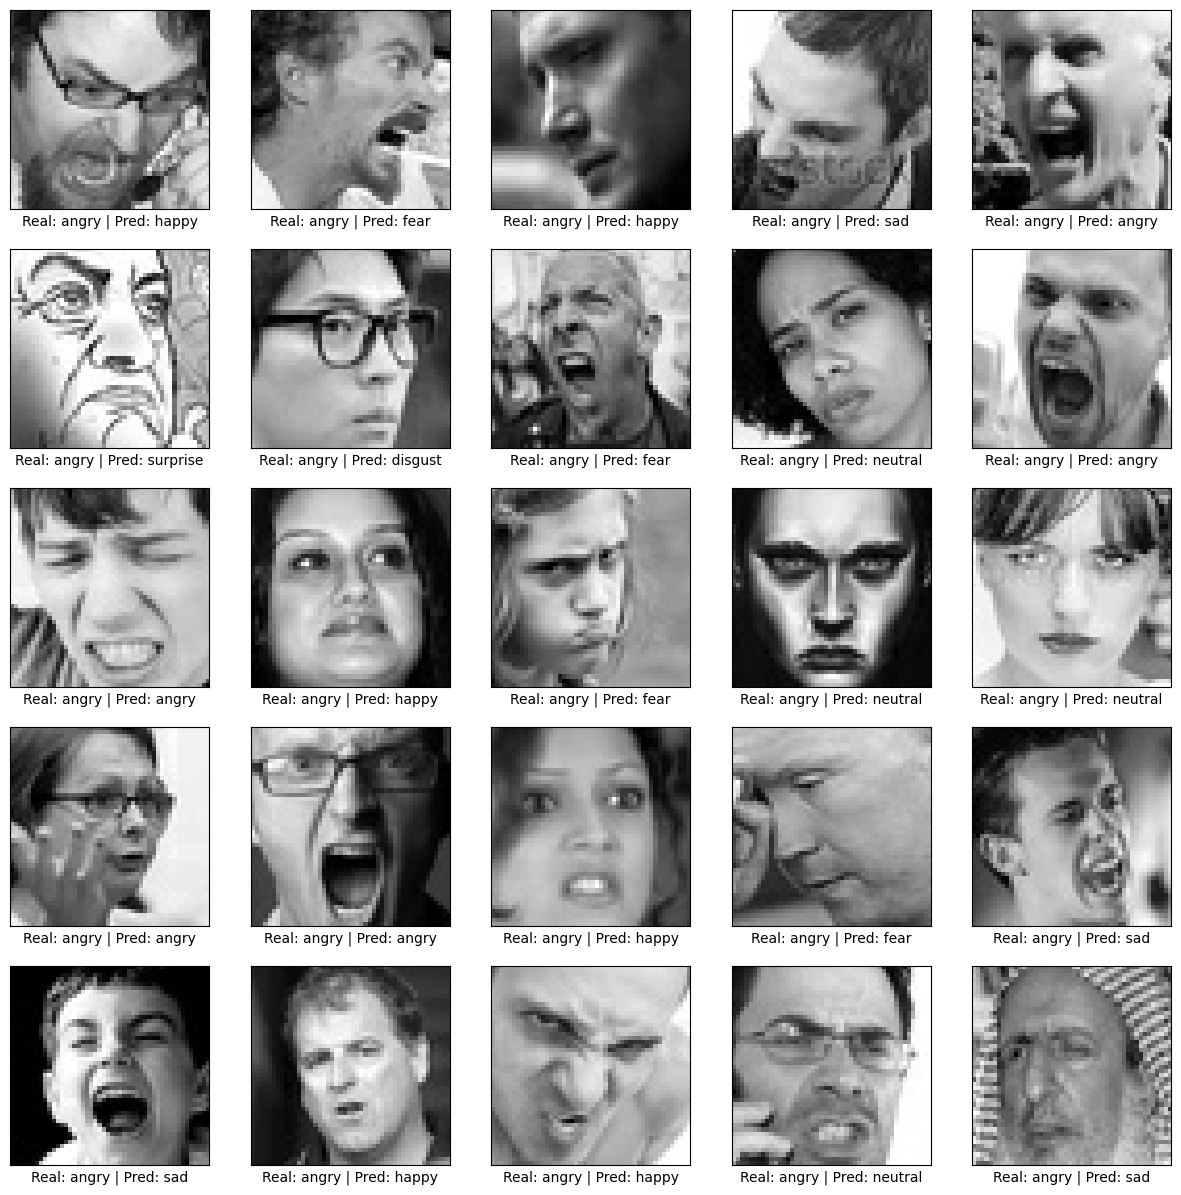

In [51]:
test_images, test_labels = next(iter(test_ds))
real = test_labels.numpy().argmax(axis=1)

plt.figure(figsize=(15, 15))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(test_images[i].numpy().squeeze(), cmap="gray")
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(f"Real: {class_names[real[i]]} | Pred: {class_names[y_pred[i]]}")
plt.show()

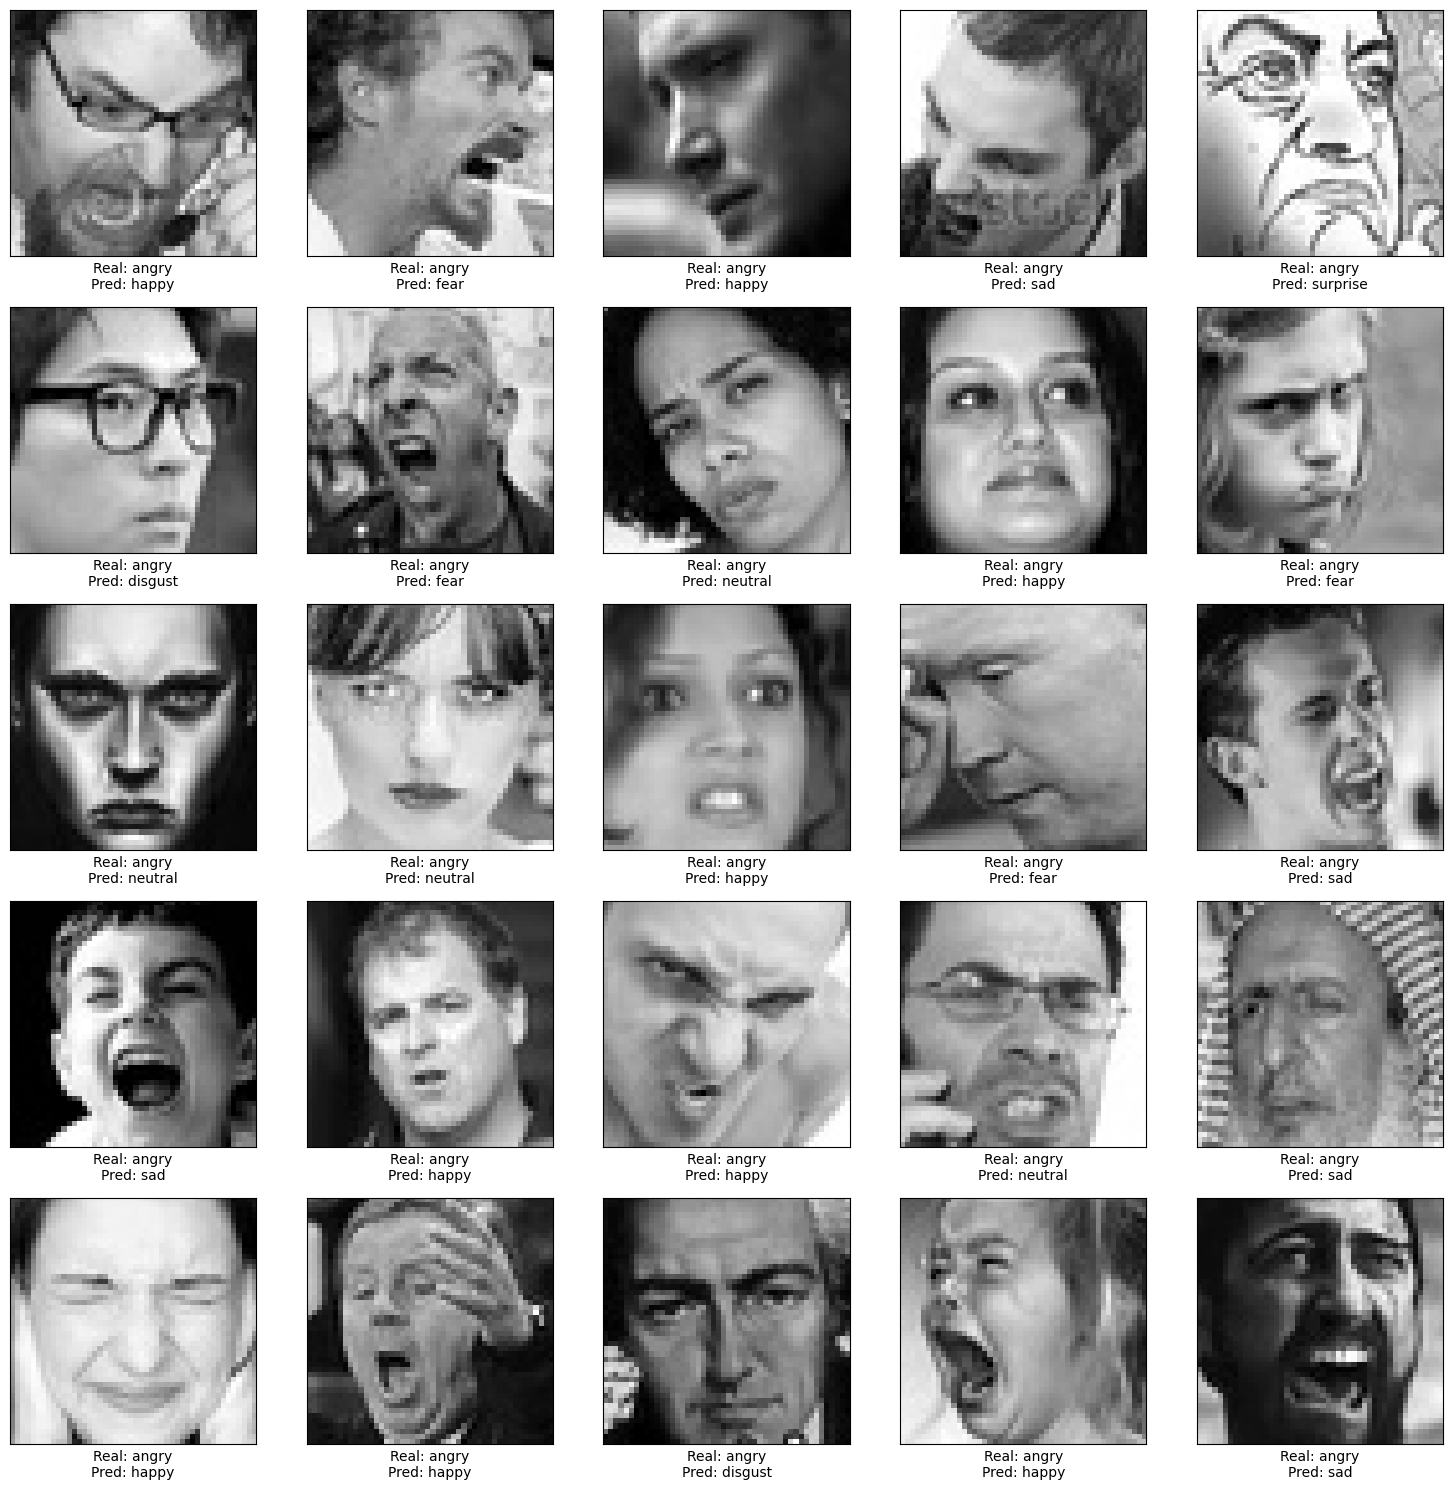

In [52]:
# Display sample of wrong or missclassification
mistakes= y_test != y_pred
wrong= np.where(mistakes)[0]

plt.figure(figsize=(15, 15))

for i in range(min(25, len(wrong))):
    idx= wrong[i]
    plt.subplot(5, 5, i + 1)
    plt.imshow(test_images[idx].numpy().squeeze(), cmap="gray")
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(f"Real: {class_names[real[idx]]}\nPred: {class_names[y_pred[idx]]}")

plt.tight_layout()
plt.show()

Some images were classified incorrectly because some facial expressions look similar. The images are only 48x48 pixels, so small details . Poor lighting or unclear facial expressions may also affect the results.

In [53]:
### model Improvement
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),loss="categorical_crossentropy",metrics=["accuracy"])

In [54]:
history2=model.fit(train_ds , validation_data=val_ds, epochs=50, callbacks=[early_stoping, model_checkpoint_callback],class_weight=class_weight_dict)

Epoch 1/50
382/382 ━━━━━━━━━━━━━━━━━━━━ 27s 53ms/step - accuracy: 0.5015 - loss: 1.1250 - val_accuracy: 0.4020 - val_loss: 1.5949
Epoch 2/50
382/382 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.5176 - loss: 1.0782 - val_accuracy: 0.4043 - val_loss: 1.5990
Epoch 3/50
382/382 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.5271 - loss: 1.0494 - val_accuracy: 0.4006 - val_loss: 1.6051
Epoch 4/50
382/382 ━━━━━━━━━━━━━━━━━━━━ 15s 40ms/step - accuracy: 0.5351 - loss: 1.0315 - val_accuracy: 0.4013 - val_loss: 1.6057
Epoch 5/50
382/382 ━━━━━━━━━━━━━━━━━━━━ 16s 40ms/step - accuracy: 0.5433 - loss: 1.0175 - val_accuracy: 0.4025 - val_loss: 1.6103
Epoch 6/50
382/382 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.5468 - loss: 1.0024 - val_accuracy: 0.4027 - val_loss: 1.6239
Epoch 7/50
382/382 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - accuracy: 0.5504 - loss: 0.9900 - val_accuracy: 0.4059 - val_loss: 1.6220
Epoch 8/50
382/382 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - accuracy: 0.5598 - loss: 0.9769 - 

In [55]:
y_pred2=model.predict(test_ds).argmax(axis=1)

113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step


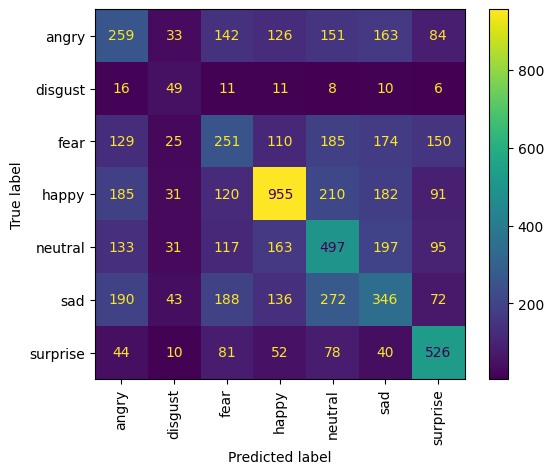

In [56]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred2, display_labels=class_names, xticks_rotation='vertical');

In [58]:
print(classification_report(y_test, y_pred2, target_names=class_names))

              precision    recall  f1-score   support

       angry       0.27      0.27      0.27       958
     disgust       0.22      0.44      0.29       111
        fear       0.28      0.25      0.26      1024
       happy       0.61      0.54      0.57      1774
     neutral       0.35      0.40      0.38      1233
         sad       0.31      0.28      0.29      1247
    surprise       0.51      0.63      0.57       831

    accuracy                           0.40      7178
   macro avg       0.37      0.40      0.38      7178
weighted avg       0.41      0.40      0.40      7178



In [59]:
# increase only 1%

In [60]:
# save the model
model.save("model.keras")


In [61]:
# check
print(train_ds.class_names)

['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [62]:
from google.colab import files
files.download("model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Gradio

In [63]:

from PIL import Image
import cv2
import numpy as np
import gradio as gr

In [64]:
class_names = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]

In [65]:
def predict(img):
    img= cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    img= cv2.resize(img, (48, 48))
    img= img.astype("float32")
    img= img.reshape(1, 48, 48, 1)
    probs = model.predict(img, verbose=0)[0]
    return {name: float(p) for name, p in zip(class_names, probs)}

In [66]:
demo= gr.Interface(
    fn=predict,
    inputs=gr.Image(sources=["upload", "webcam"], type="numpy"),
    outputs=gr.Label(num_top_classes=7),
    title="Facial Emotion Recognition",
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0104397f26a9234c06.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
